# PART B: ML Model

- use ml4health_cohort.parquet dataset from part A to build model.
- 60/20/20 train/val/test split + 5-fold cross-validation for tuning.
- use **XGBoost** as the black-box.
- Add a **SOFA-only baseline**, giving the brief's "baseline + interpretable + black-box" set.
- Interpretability: logistic-regression coefficients and SHAP / gain importance for XGBoost.



### Access Data

In [25]:
import pandas as pd
df = pd.read_parquet("ml4health_cohort.parquet")

In [26]:
print(df.shape)
print(df["mortality"].mean())
df.head()

(65366, 25)
0.10840498118287795


,subject_id,hadm_id,stay_id,intime,outtime,sex,race,insurance,mortality,age,...,platelets_min,bun_max,wbc_max,gcs_min,lactate_max,sofa,charlson,lactate_max_measured,sofa_measured,charlson_measured
0,10000032,29079034,39553978,2180-07-23 14:00:00,2180-07-23 23:50:47,F,White,Medicaid,0,52,...,94.000,33.000,4.100,14.000,NaN,10,3,0,1,1
1,10000690,25860671,37081114,2150-11-02 19:37:00,2150-11-06 17:03:17,F,White,Medicare,0,86,...,199.000,21.000,7.500,12.000,NaN,5,5,0,1,1
2,10000980,26913865,39765666,2189-06-27 08:42:00,2189-06-27 20:38:27,F,Black,Medicare,0,73,...,197.000,38.000,5.400,15.000,NaN,2,8,0,1,1
3,10001217,24597018,37067082,2157-11-20 19:18:02,2157-11-21 22:08:00,F,White,Private,0,55,...,283.000,10.000,19.000,15.000,NaN,0,1,0,1,1
4,10001725,25563031,31205490,2110-04-11 15:52:22,2110-04-12 23:59:56,F,White,Private,0,46,...,299.000,18.000,20.100,15.000,NaN,1,1,0,1,1


In [27]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.float_format", lambda v: f"{v:.3f}")
PALETTE = ["#1E2761","#3F51B5","#F4B942","#028090","#B85042","#5A6182","#00A896","#990011"]
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True,"grid.alpha": 0.25,
                     "axes.axisbelow": True,"font.size": 11})

NUMERIC = ["age","heart_rate_mean","sbp_min","spo2_min","resp_rate_mean",
           "creatinine_max","platelets_min","bun_max","wbc_max","gcs_min",
           "lactate_max","sofa","charlson"]
NUMERIC = [c for c in NUMERIC if c in df.columns]
NUMERIC += ["lactate_max_measured"] # only lactate has missing values (46%) in part a
SENSITIVE = ["race","sex","insurance"]
RACE_ORDER = ["White","Black","Hispanic","Asian","Other","Unknown"]
def order_races(idx):
    return [r for r in RACE_ORDER if r in list(idx)] + [r for r in idx if r not in RACE_ORDER]
print("cohort:", df.shape)
print(len(NUMERIC), NUMERIC)


cohort: (65366, 25)
14 ['age', 'heart_rate_mean', 'sbp_min', 'spo2_min', 'resp_rate_mean', 'creatinine_max', 'platelets_min', 'bun_max', 'wbc_max', 'gcs_min', 'lactate_max', 'sofa', 'charlson', 'lactate_max_measured']


### Train/validation/test split (60/20/20)

In [28]:
from sklearn.model_selection import train_test_split

X = df[NUMERIC].astype("float64").copy()
y = df["mortality"].astype(int).copy()
S = df[SENSITIVE].copy()

# 60/20/20 split
X_tmp, X_test, y_tmp, y_test, S_tmp, S_test = train_test_split(X, y, S, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
X_train, X_val, y_train, y_val, S_train, S_val = train_test_split(X_tmp, y_tmp, S_tmp, test_size=0.25, stratify=y_tmp, random_state=RANDOM_STATE)

for name, y_part in [("train", y_train),("validation", y_val),("test", y_test)]:
    print(f"{name:10} n={len(y_part):>6,} mortality={y_part.mean():.3f}")

train      n=39,219 mortality=0.108
validation n=13,073 mortality=0.108
test       n=13,074 mortality=0.108


### Preprocessing pipeline

In [29]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

pre = ColumnTransformer([("num", Pipeline
                        ([("impute", SimpleImputer(strategy="median")),
                        ("scale", StandardScaler())]), NUMERIC)])

### Build model

- **Baseline:** logistic regression on the SOFA score alone — the established ICU severity signal.
- **Interpretable:** full logistic regression.
- **Black-box:** XGBoost, tuned by 5-fold CV.

In [30]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

# Baseline: SOFA only
sofa_col = ["sofa"]
pre_sofa = ColumnTransformer([("num", Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler())]), sofa_col)])
baseline = Pipeline([("pre", pre_sofa),
                    ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))])

# Interpretable: all features
logistic = Pipeline([("pre", pre),
                    ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))])



cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
lr_search = GridSearchCV(logistic, {"clf__C":[0.001,0.01,0.1,1,10,100]},
                         scoring="average_precision", cv=cv, n_jobs=-1)
lr_search.fit(X_train, y_train)
logistic = lr_search.best_estimator_
print("best CV AUPRC:", round(lr_search.best_score_,3))
print("best C:", lr_search.best_params_)

baseline.fit(X_train, y_train)
print("fitted: Baseline (SOFA), Logistic Regression")

best CV AUPRC: 0.493
best C: {'clf__C': 0.01}
fitted: Baseline (SOFA), Logistic Regression


- Note: Class imbalance (10.8% mortality) was addressed through stratified splitting,
stratified 5-fold cross-validation, a threshold-independent primary metric
(AUPRC), and selection of the decision threshold on the validation set rather
than the default of 0.5. Class weighting was not used because it inflated
predicted probabilities without improving discrimination.

In [31]:

from xgboost import XGBClassifier

# removed: spw = float((y_train==0).sum()/(y_train==1).sum())

xgb = Pipeline([("pre",pre),("clf",XGBClassifier(
        eval_metric="logloss", tree_method="hist", random_state=RANDOM_STATE))])
grid = {"clf__n_estimators":[300,500,800],"clf__max_depth":[3,4,6],
        "clf__learning_rate":[0.03,0.06,0.1],"clf__subsample":[0.8,1.0],
        "clf__colsample_bytree":[0.8,1.0]}

search = RandomizedSearchCV(xgb, grid, n_iter=15, scoring="average_precision",
                            cv=cv, random_state=RANDOM_STATE, n_jobs=-1)
search.fit(X_train, y_train)
blackbox = search.best_estimator_
print("best CV AUPRC:", round(search.best_score_,3))
print("best params:", search.best_params_)


best CV AUPRC: 0.541
best params: {'clf__subsample': 0.8, 'clf__n_estimators': 800, 'clf__max_depth': 4, 'clf__learning_rate': 0.03, 'clf__colsample_bytree': 0.8}


In [32]:
from sklearn.model_selection import cross_val_score

models = {"Baseline (SOFA)":baseline,"Logistic Regression":logistic,
          "XGBoost":blackbox}

for n,m in models.items():
    s = cross_val_score(m, X_train, y_train, cv=cv, scoring="average_precision", n_jobs=-1)
    print(f"{n:20} CV AUPRC = {s.mean():.3f} ± {s.std():.3f}")

Baseline (SOFA)      CV AUPRC = 0.341 ± 0.022
Logistic Regression  CV AUPRC = 0.493 ± 0.022
XGBoost              CV AUPRC = 0.541 ± 0.023


**Primary metric: AUPRC.**
- The outcome is imbalanced (10.8% mortality), and
  AUPRC focuses on how well the model identifies the positive class (deaths),
  so it reflects the clinically relevant task. It was also the scoring metric
  for 5-fold CV hyperparameter tuning, so model selection and evaluation use
  the same criterion. **AUROC is reported as a secondary metric** for
  comparability with prior ICU mortality studies, which typically report it.

Validation set:
                     AUROC  AUPRC  Brier
Baseline (SOFA)      0.758  0.330  0.084
Logistic Regression  0.831  0.478  0.074
XGBoost              0.873  0.531  0.070


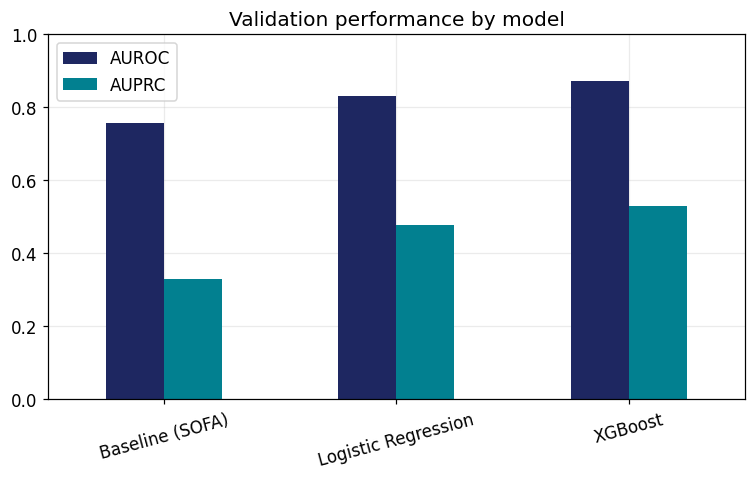

In [33]:
def metrics(m,X,yy):
    p=m.predict_proba(X)[:,1]
    return {"AUROC":roc_auc_score(yy,p),"AUPRC":average_precision_score(yy,p), "Brier":brier_score_loss(yy,p)}
val_tbl = pd.DataFrame({n:metrics(m,X_val,y_val) for n,m in models.items()}).T
print("Validation set:"); print(val_tbl.round(3))

fig,ax=plt.subplots(figsize=(7,4.5))
val_tbl[["AUROC","AUPRC"]].plot(kind="bar",ax=ax,color=[PALETTE[0],PALETTE[3]],rot=15)
ax.set_title("Validation performance by model"); ax.set_ylim(0,1); ax.legend()
plt.tight_layout(); plt.show()

- Performance improves at each step: SOFA baseline < logistic regression < XGBoost.
- SOFA-only AUROC of 0.758 is in line with the range commonly reported for SOFA in ICU mortality prediction (roughly 0.7–0.8).
- AUPRC should be read against the prevalence of 0.108. SOFA (0.330) is about 3× that level and XGBoost (0.531) about 5×.
- Most of the gain comes from adding clinical features (SOFA → logistic regression: AUPRC +0.148, AUROC +0.073). Moving to XGBoost adds a further +0.053 and +0.042, so the more complex model contributes less than the features themselves.
- Brier scores (0.084, 0.074, 0.070) are all below the prevalence-only reference of 0.097, indicating that predicted probabilities are reasonably calibrated without class weighting.

### Result

TEST set:
                     AUROC  AUPRC  Brier
Baseline (SOFA)      0.771  0.357  0.082
Logistic Regression  0.843  0.502  0.072
XGBoost              0.880  0.557  0.068


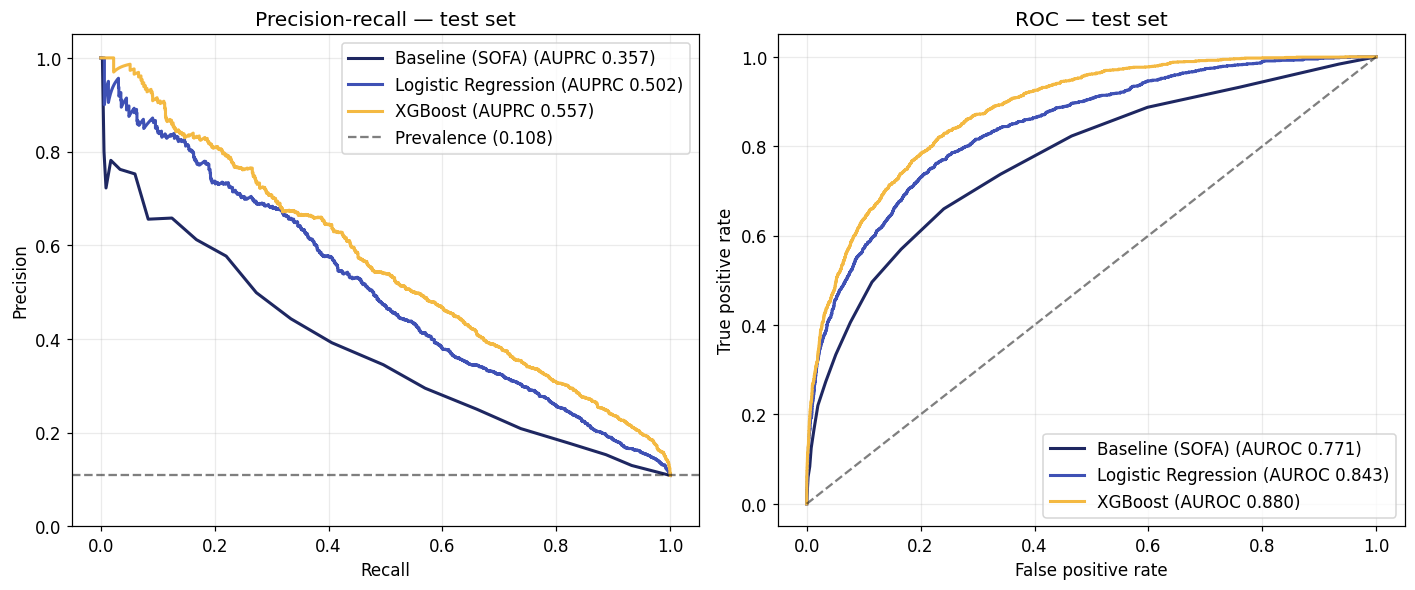

In [34]:
from sklearn.metrics import roc_curve, precision_recall_curve

test_tbl = pd.DataFrame({n:metrics(m,X_test,y_test) for n,m in models.items()}).T
print("TEST set:"); print(test_tbl.round(3))

fig,axes=plt.subplots(1,2,figsize=(13,5.5))

for (n,m),c in zip(models.items(),PALETTE):
    p=m.predict_proba(X_test)[:,1]
    # left: precision-recall (primary metric)
    prec,rec,_=precision_recall_curve(y_test,p)
    axes[0].plot(rec,prec,color=c,lw=2,label=f"{n} (AUPRC {average_precision_score(y_test,p):.3f})")
    # right: ROC (secondary metric)
    fprc,tprc,_=roc_curve(y_test,p)
    axes[1].plot(fprc,tprc,color=c,lw=2,label=f"{n} (AUROC {roc_auc_score(y_test,p):.3f})")

axes[0].axhline(y_test.mean(),color="k",ls="--",alpha=0.5,label=f"Prevalence ({y_test.mean():.3f})")
axes[0].set_xlabel("Recall"); axes[0].set_ylabel("Precision"); axes[0].set_ylim(0,1.05)
axes[0].set_title("Precision-recall — test set"); axes[0].legend(loc="upper right")

axes[1].plot([0,1],[0,1],"k--",alpha=0.5)
axes[1].set_xlabel("False positive rate"); axes[1].set_ylabel("True positive rate")
axes[1].set_title("ROC — test set"); axes[1].legend(loc="lower right")

plt.tight_layout(); plt.show()

**Test set results:**

- **Ranking is consistent across both curves:** XGBoost > logistic regression > SOFA baseline across almost the entire range. The XGBoost and logistic regression curves come close at low recall.
- **Precision-recall:** AUPRC 0.357 (SOFA), 0.502 (logistic regression), 0.557 (XGBoost) against a prevalence of 0.108, i.e. roughly 3×, 5× and 5× the chance level.
- **ROC:** AUROC 0.771, 0.843, 0.880. All well above the 0.5 chance line.
- **Largest gain comes from adding clinical features** (SOFA → logistic regression: AUPRC +0.145, AUROC +0.072). Moving to XGBoost adds less (AUPRC +0.055, AUROC +0.037).
- **Good discrimination, but false alarms remain common:** precision falls steadily as recall rises, so at high recall most patients flagged as high-risk survive.
- **Probabilities are reasonably calibrated:** Brier scores (0.082, 0.072, 0.068) are all below the prevalence-only reference of 0.097.
- **Test results are close to validation** (XGBoost AUPRC 0.531 → 0.557, AUROC 0.873 → 0.880), with no sign of overfitting.

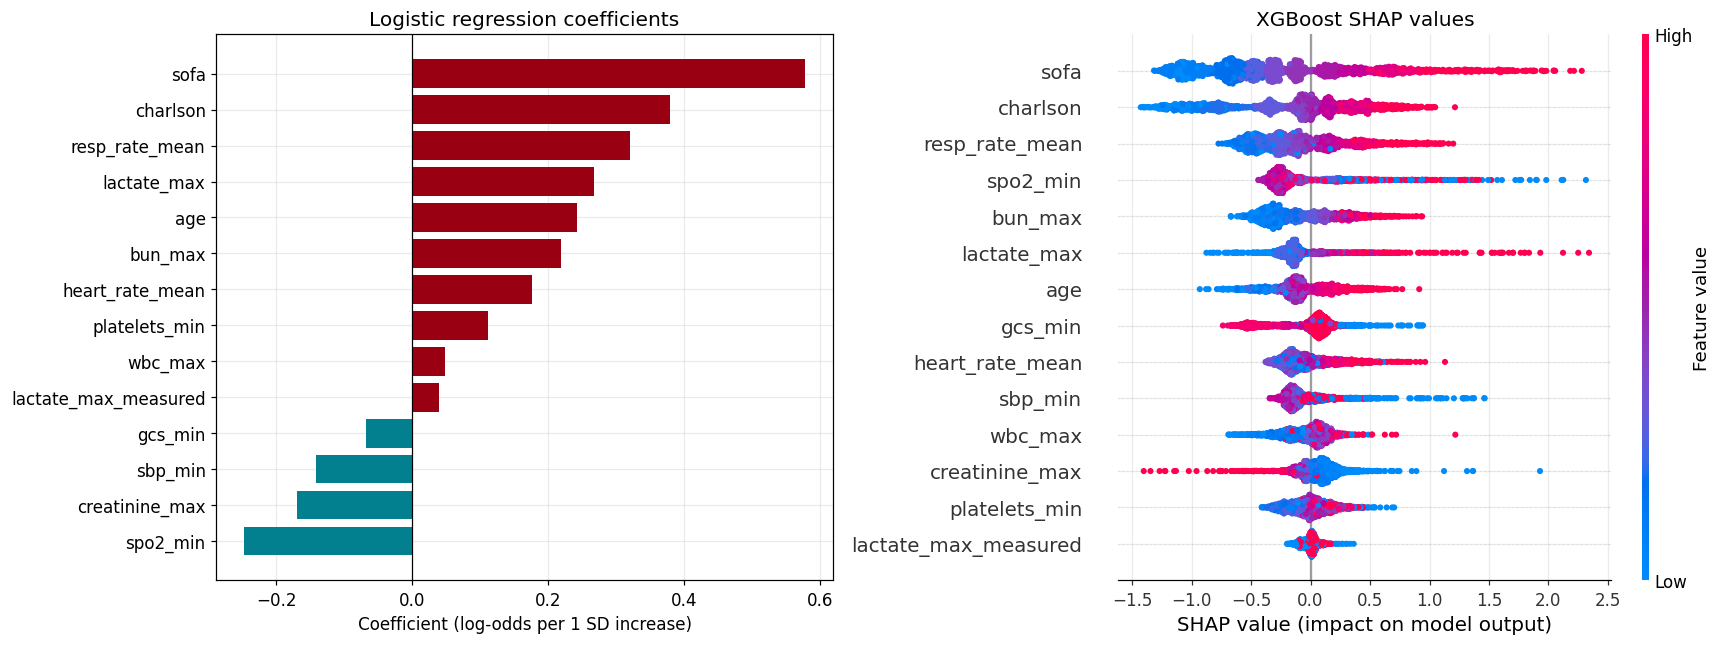

In [35]:
import shap

# data for both panels
coefs = pd.Series(logistic.named_steps["clf"].coef_[0], index=NUMERIC).sort_values()
Xt_test = blackbox.named_steps["pre"].transform(X_test)
sv = shap.Explainer(blackbox.named_steps["clf"])(Xt_test[:2000])

fig,axes=plt.subplots(1,2,figsize=(16,6))

# left: logistic regression coefficients
axes[0].barh(coefs.index, coefs.values,
             color=[PALETTE[7] if v>0 else PALETTE[3] for v in coefs.values])
axes[0].axvline(0,color="k",lw=0.8)
axes[0].set_xlabel("Coefficient (log-odds per 1 SD increase)")
axes[0].set_title("Logistic regression coefficients")

# right: SHAP for XGBoost
plt.sca(axes[1])
shap.summary_plot(sv, features=Xt_test[:2000], feature_names=NUMERIC,
                  show=False, plot_size=None, rng=np.random.default_rng(RANDOM_STATE))
axes[1].set_title("XGBoost SHAP values")

plt.tight_layout(); plt.show()

**Feature importance:**

- **Top features agree:** SOFA, Charlson and respiratory rate rank 1st–3rd in both models; `lactate_max_measured` ranks last in both.
- **Directions agree:** higher SOFA, Charlson, lactate and age raise risk; lower SpO2, GCS and SBP raise risk.
- **`creatinine_max` is negative in both models.** Deaths have higher creatinine when viewed alone (median 1.5 vs 1.0), so this reflects the residual effect after adjusting for SOFA and BUN, not a model artefact.
- **`platelets_min` is positive in logistic regression but weak and mixed in SHAP,** so the coefficient should not be interpreted in isolation.
- **XGBoost captures threshold effects:** for `spo2_min`, `sbp_min` and `lactate_max`, risk rises sharply only at extreme values. Logistic regression cannot represent this, which may partly explain XGBoost's better performance.
- **Compare rankings and directions only.** Coefficients and SHAP values are on different scales, so their magnitudes are not directly comparable.

### Export as paraquet file for auditing

In [36]:
out = df.copy()      # all 25 columns from Part A

# label each row with its split
out["split"] = "train"
out.loc[X_val.index, "split"] = "validation"
out.loc[X_test.index, "split"] = "test"

# predicted probability of death from each model
for name,col in [("Baseline (SOFA)","p_sofa"),("Logistic Regression","p_lr"),("XGBoost","p_xgb")]:
    out[col] = models[name].predict_proba(X)[:,1]

out.to_parquet("ml4health_predictions.parquet", index=False)
print(out.shape); print(out["split"].value_counts())

(65366, 29)
split
train         39219
test          13074
validation    13073
Name: count, dtype: int64
